In [1]:
import os, re, sys, gc, json, cv2, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datetime import datetime
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

sys.path.append('..')
from Dataset.index import Normalization, showTile
from Network.index import ModelNetwork
from Transforms.index import Transforms
from Metrics.ConfusionMatrix.index import ConfusionMatrix
from Metrics.ROC.index import ROC

cv2.setNumThreads(1)    # O DATALOADER CRIA WORKERS POR FORK DEPOIS DO CV2: SEM ISSO OS FILHOS TRAVAM
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'

('2.7.1+cu128', 'NVIDIA GeForce RTX 5070')

# MODELOS
- `BASE_PATH` é a pasta dos `model_N/`: `'Backup'` ou `'../Documents/Backups/<campanha>'`
- `MODELS` são os modelos testados; `[]` pega todos os `model_N` da pasta
- `DATASET` é onde todos são testados; `None` testa cada um no dataset em que treinou
- `N_PLOTS` é quantos tiles de teste de cada modelo aparecem em PREDIÇÕES
- `ROC_CURVE` liga a curva ROC; os voxels entram na mesma passada da rede, sem outra predição. `False` deixa só a matriz de confusão
- `SAVE_PATH` é onde ficam as figuras de cada modelo: `<SAVE_PATH>/<modelo>/matrix.png` e `roc.png`, com `_<dataset>` no nome quando o teste não é no dataset do treino; `None` só mostra

In [2]:
BASE_PATH = 'Backup/'
MODELS    = []
DATASET   = None
N_PLOTS   = 3
ROC_CURVE = True
SAVE_PATH = BASE_PATH

models = MODELS or sorted((name for name in os.listdir(BASE_PATH) if re.fullmatch(r'model_\d+', name)), key=lambda name: int(name.split('_')[-1]))
models

['model_1',
 'model_2',
 'model_3',
 'model_4',
 'model_5',
 'model_6',
 'model_7',
 'model_8',
 'model_9',
 'model_10',
 'model_11']

In [3]:
# Parameters
MODELS = ["model_11"]
models = ["model_11"]


# SPLITS DOS DADOS
- O `test_size` vem do `division` do `info.json` de cada modelo (backup de antes do `division` guarda no `processing`): o split do treino é refeito com `random_state=42` e as contagens têm de bater com o `n_images` gravado
- Em outro `DATASET`, o teste é o split dele com o mesmo `test_size`, sem os tiles que o modelo viu no treino e na validação (os mixes apontam para os arquivos dos datasets de origem)
- O `DataBase.csv` testado tem de estar no `scaling` em que o modelo treinou
- Modelo com split ou `scaling` que não bate fica fora, com o motivo no `status`

In [4]:
# TILES DE TESTE DE UM MODELO NO DATASET PEDIDO; ERRO QUANDO O SCALING OU O SPLIT NÃO BATEM COM O TREINO
def getTest(info, dataset):
    options   = info['processing']
    division  = info.get('division', options)
    database  = f'../Dataset/{dataset}/DataBase.csv'
    scaling   = options.get('scaling', Normalization.DEFAULT)
    formatted = Normalization.read(database)

    if formatted != scaling:
        raise ValueError(f'{dataset} em {formatted!r}, treino em {scaling!r}')

    df         = pd.read_csv(f'../Dataset/{options["dataset"]}/DataBase.csv')
    seen, test = train_test_split(df, test_size=division['test_size'], random_state=42)
    images     = division['n_images']

    if (len(df), len(test)) != (images['total'], images['test']):
        raise ValueError(f'split {len(df)}/{len(test)}, treino {images["total"]}/{images["test"]}')

    if dataset == options['dataset']:
        return test

    test = train_test_split(pd.read_csv(database), test_size=division['test_size'], random_state=42)[1]
    return test[~test.img_path.isin(seen.img_path)]

In [5]:
selected, rows = {}, []

for name in models:
    info    = json.load(open(f'{BASE_PATH}/{name}/info.json'))
    dataset = DATASET or info['processing']['dataset']

    try:
        selected[name] = {'info': info, 'dataset': dataset, 'test': getTest(info, dataset)}
        status = f'{len(selected[name]["test"])} tiles'
    except (ValueError, FileNotFoundError) as error:
        status = f'fora: {error}'

    rows.append({'modelo': name, 'rede': info['model']['network'], 'treino': info['processing']['dataset'], 'teste': dataset, 'scaling': info['processing'].get('scaling', Normalization.DEFAULT), 'test_iou': info['trainer'].get('test_iou'), 'status': status})

pd.DataFrame(rows)

,modelo,rede,treino,teste,scaling,test_iou,status
0,model_11,resaceunet_grva,dataset_74,dataset_74,normalize,0.740451,10 tiles


# DATASET
- Sem `crop` no `augmentations`, cada tile de teste é cortado em blocos da janela do modelo (o último encosta no fim do volume)
- Com `crop`, o tile vai inteiro e o `Transforms` prediz por janela deslizante, com o mesmo `overlap`, `mode` e lote do treino: a mesma conta do `test_iou` gravado

In [6]:
# BLOCOS DA JANELA DO MODELO EM CADA TILE DE TESTE; window=None É O TILE INTEIRO
class PredictDataset(Dataset):
    def __init__(self, df, window):
        self.df     = df.reset_index(drop=True)
        shape       = np.load(self.df.img_path.iloc[0], mmap_mode='r').shape
        self.window = tuple(min(int(w), int(s)) for w, s in zip(window or shape, shape))
        starts      = [sorted(set(range(0, s - w + 1, w)) | {s - w}) for s, w in zip(shape, self.window)]    # O ÚLTIMO ENCOSTA NO FIM DO VOLUME
        self.blocks = list(itertools.product(range(len(self.df)), *starts))

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, index):
        row, d, h, w = self.blocks[index]
        wd, wh, ww   = self.window
        item         = self.df.iloc[row]
        img, mask    = (np.asarray(np.load(path, mmap_mode='r')[d:d + wd, h:h + wh, w:w + ww], np.float32) for path in (item.img_path, item.mask_path))
        return torch.tensor(img).unsqueeze(0), torch.tensor(mask, dtype=torch.long).unsqueeze(0)

# DATA LOADER
- Um loader por modelo, com o lote pelo orçamento de 128³ voxels por passada

In [7]:
NUM_WORKERS = 2
VOXELS      = 128 ** 3    # ORÇAMENTO DE CADA PASSADA DA REDE
MAX_BATCH   = 256

for test in selected.values():
    options            = test['info']['processing']
    test['transforms'] = Transforms(options.get('augmentations'), batch=options.get('batch_size'))
    dataset            = PredictDataset(test['test'], None if test['transforms'].window else test['info']['model']['img_size'])
    batch              = int(np.clip(VOXELS // int(np.prod(dataset.window)), 1, MAX_BATCH))
    test['loader']     = DataLoader(dataset, batch_size=batch, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

pd.DataFrame([{'modelo': name, 'janela': test['loader'].dataset.window, 'recorte': test['transforms'].window, 'blocos': len(test['loader'].dataset), 'lote': test['loader'].batch_size} for name, test in selected.items()])

,modelo,janela,recorte,blocos,lote
0,model_11,"(128, 128, 128)",None,10,1


# DADOS DE TESTE
- Para cada modelo: carrega os pesos, prediz os blocos de teste e soma os voxels de todos os tiles na `ConfusionMatrix` (`Metrics/ConfusionMatrix`) antes de dividir, a mesma conta do `test_iou` do treino
- Com `ROC_CURVE`, os logits do mesmo lote também entram no histograma da `ROC` (`Metrics/ROC`)
- As máscaras preditas dos `N_PLOTS` primeiros blocos ficam guardadas para as figuras, e a rede é solta antes do próximo modelo
- No dataset em que o modelo treinou, o `iou` tem de repetir o `test_iou` gravado

In [8]:
def loadNetwork(name, info):
    network = ModelNetwork(**info['model'])
    network.model.load_state_dict(torch.load(f'{BASE_PATH}/{name}/model.pth', map_location=network.device)['model'])
    network.model.eval()
    return network


# VOXELS DO TESTE INTEIRO NA MATRIZ (E NA ROC, QUANDO ELA VEM) E AS MÁSCARAS PREDITAS DOS N_PLOTS PRIMEIROS BLOCOS
def evaluate(network, transforms, loader, amp=False, roc=None):
    matrix, preds = ConfusionMatrix(), []

    with torch.no_grad(), torch.autocast('cuda', enabled=amp):
        for imgs, masks in tqdm(loader, desc='Avaliando'):
            imgs, masks = imgs.to(network.device), masks.to(network.device)
            logits      = transforms.infer(network.model, imgs)
            pred        = logits.argmax(dim=1).bool() if network.multiclass else torch.sigmoid(logits).squeeze(1) > 0.5
            matrix.update(pred, masks.squeeze(1).bool())

            if roc is not None:
                roc.update(logits, masks)

            preds += [block.squeeze().cpu().numpy() for block in pred[:N_PLOTS - len(preds)]]

    return matrix, preds


for name, test in selected.items():
    network     = loadNetwork(name, test['info'])
    test['roc'] = ROC() if ROC_CURVE else None
    test['matrix'], test['preds'] = evaluate(network, test['transforms'], test['loader'], amp=test['info']['processing'].get('amp', False), roc=test['roc'])
    del network
    gc.collect(); torch.cuda.empty_cache()

counts = {name: dict(zip(('tp', 'fp', 'fn', 'tn'), test['matrix'].counts)) for name, test in selected.items()}
pd.DataFrame(counts).T

Avaliando:   0%|                                                                                                              | 0/10 [00:00<?, ?it/s]

Avaliando:  10%|██████████▏                                                                                           | 1/10 [00:00<00:04,  1.99it/s]

Avaliando:  30%|██████████████████████████████▌                                                                       | 3/10 [00:00<00:01,  5.53it/s]

Avaliando:  50%|███████████████████████████████████████████████████                                                   | 5/10 [00:00<00:00,  8.18it/s]

Avaliando:  70%|███████████████████████████████████████████████████████████████████████▍                              | 7/10 [00:00<00:00, 10.12it/s]

Avaliando:  90%|███████████████████████████████████████████████████████████████████████████████████████████▊          | 9/10 [00:01<00:00, 11.53it/s]

Avaliando: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:01<00:00,  8.81it/s]

,tp,fp,fn,tn
model_11,1370258,251839,228493,19120930


In [9]:
scores    = {name: {**test['matrix'].metrics(), **({'auc': test['roc'].auc} if test['roc'] else {})} for name, test in selected.items()}
testTable = pd.DataFrame([{'modelo': name, 'rede': test['info']['model']['network'], 'treino': test['info']['processing']['dataset'], 'teste': test['dataset'], 'tiles': len(test['test']), 'test_iou': test['info']['trainer'].get('test_iou'), **scores[name]} for name, test in selected.items()])
testTable

,modelo,rede,treino,teste,tiles,test_iou,accuracy,precision,recall,iou,f1,auc
0,model_11,resaceunet_grva,dataset_74,dataset_74,10,0.740451,0.977096,0.844745,0.85708,0.740444,0.850868,0.992158


# SALVANDO NO INFO.JSON
- As métricas de cada modelo vão para `test.<dataset>` do `info.json` dele: as razões, a `auc` (com `ROC_CURVE`), os voxels (`tp`, `fp`, `fn`, `tn`), quantos tiles, o `scaling` e a data
- Testar de novo no mesmo dataset substitui a entrada; outro dataset entra ao lado

In [10]:
saved = {}

for name, test in selected.items():
    path = f'{BASE_PATH}/{name}/info.json'
    info = json.load(open(path))

    saved[name] = {
        'tiles': len(test['test']),
        'scaling': info['processing'].get('scaling', Normalization.DEFAULT),
        **scores[name],
        **counts[name],
        'timestamp': datetime.now().strftime('%d/%m/%y %H:%M:%S')
    }
    info.setdefault('test', {})[test['dataset']] = saved[name]

    with open(path, 'w', encoding='utf-8') as file:
        json.dump(info, file, ensure_ascii=False, indent=4)

pd.DataFrame(saved).T

,tiles,scaling,accuracy,precision,recall,iou,f1,auc,tp,fp,fn,tn,timestamp
model_11,10,normalize,0.977096,0.844745,0.85708,0.740444,0.850868,0.992158,1370258,251839,228493,19120930,24/11/26 07:24:14


# MATRIZ DE CONFUSÃO
- A conta e a figura ficam em `Metrics/ConfusionMatrix`: linha = rótulo, coluna = predição, a cor é a fração da linha e o texto traz os voxels
- Com `SAVE_PATH`, cada modelo grava a sua em `<SAVE_PATH>/<modelo>/matrix.png`

Backup//model_11/matrix.png


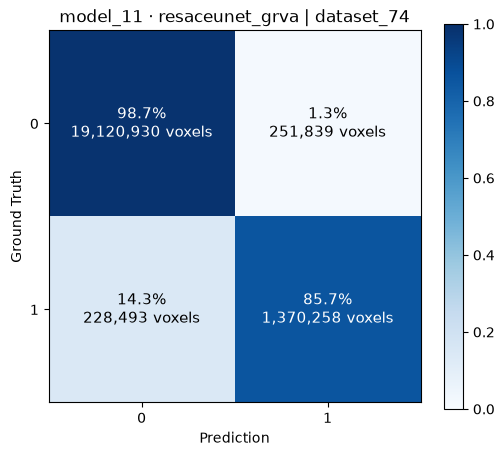

In [11]:
# FIGURA DE UM MODELO EM <SAVE_PATH>/<modelo>/<figura>.png; TESTADO FORA DO DATASET DO TREINO, O NOME GANHA _<dataset>
def figurePath(name, test, figure):
    suffix = '' if test['dataset'] == test['info']['processing']['dataset'] else f"_{test['dataset']}"
    os.makedirs(f'{SAVE_PATH}/{name}', exist_ok=True)
    return f'{SAVE_PATH}/{name}/{figure}{suffix}.png'


titles = {name: f"{name} · {test['info']['model']['network']} | {test['dataset']}" for name, test in selected.items()}

if SAVE_PATH:
    for name, test in selected.items():
        print(test['matrix'].save(figurePath(name, test, 'matrix'), title=titles[name]))

ConfusionMatrix.grid({titles[name]: test['matrix'] for name, test in selected.items()})
plt.show()

# CURVA ROC
- Só com `ROC_CURVE = True`; a conta e as figuras ficam em `Metrics/ROC`
- É por voxel, com todos os tiles de teste juntos, a mesma base da matriz: cada lote soma num histograma de 4000 faixas de log-odds em [−20, 20] quantos voxels de falha e de fundo caem em cada faixa, sem guardar as probabilidades
- O log-odds 0 é o limiar 0,5: o ● de cada curva é o ponto da matriz de confusão (na sigmoide sob AMP pode diferir em poucos voxels, porque o fp16 arredonda a sigmoide para 0,5)
- A AUC é o trapézio entre limiares vizinhos (voxels da mesma faixa contam como empate) e bate com o `roc_auc_score` do sklearn em ~1e-6
- A ★ é o limiar do melhor índice de Youden (TPR − FPR)
- Com `SAVE_PATH`, cada modelo grava a sua em `<SAVE_PATH>/<modelo>/roc.png`; a tabela traz a AUC, o ponto 0,5 e o de Youden

Backup//model_11/roc.png


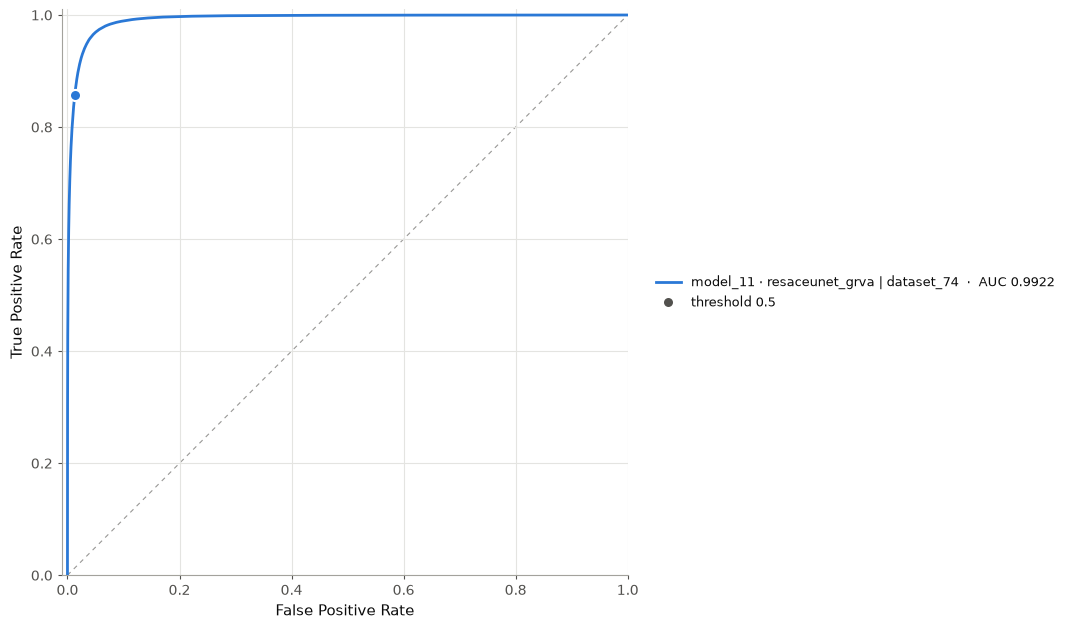

,auc,tpr_0.5,fpr_0.5,youden_threshold,youden_tpr,youden_fpr,youden_j
model_11,0.992158,0.857119,0.013003,0.010772,0.965375,0.046079,0.919297


In [12]:
curves = {name: test['roc'] for name, test in selected.items() if test['roc'] is not None}

if SAVE_PATH:
    for name, curve in curves.items():
        print(curve.save(figurePath(name, selected[name], 'roc'), title=titles[name]))

if curves:
    ROC.compare({titles[name]: curve for name, curve in curves.items()})
    plt.show()

pd.DataFrame({name: curve.summary() for name, curve in curves.items()}).T if curves else print('ROC_CURVE = False: sem curva ROC nesta rodada')

# PREDIÇÕES
- Os `N_PLOTS` primeiros blocos de teste de cada modelo: verde onde a predição acerta a falha, vermelho o falso alarme, azul a falha não detectada

model_11 · resaceunet_grva | dataset_74/images/img_0132.npy


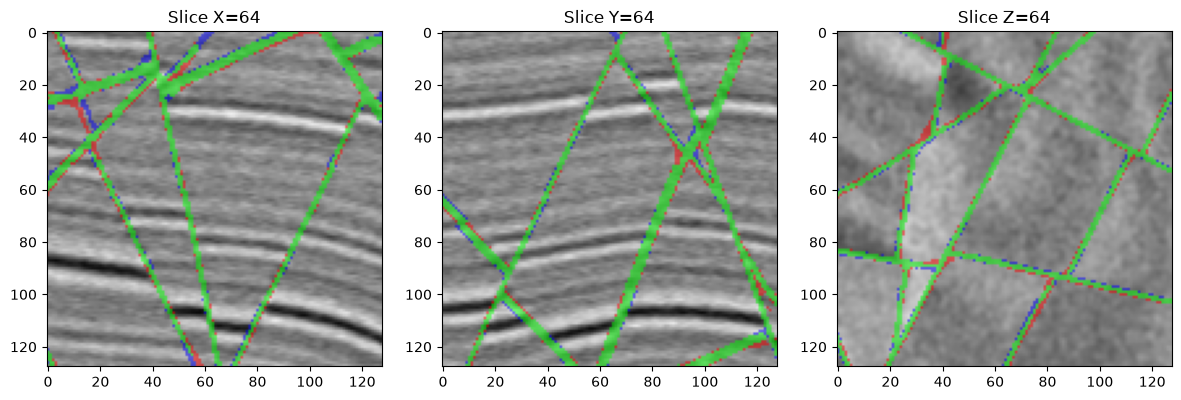

model_11 · resaceunet_grva | dataset_74/images/img_0148.npy


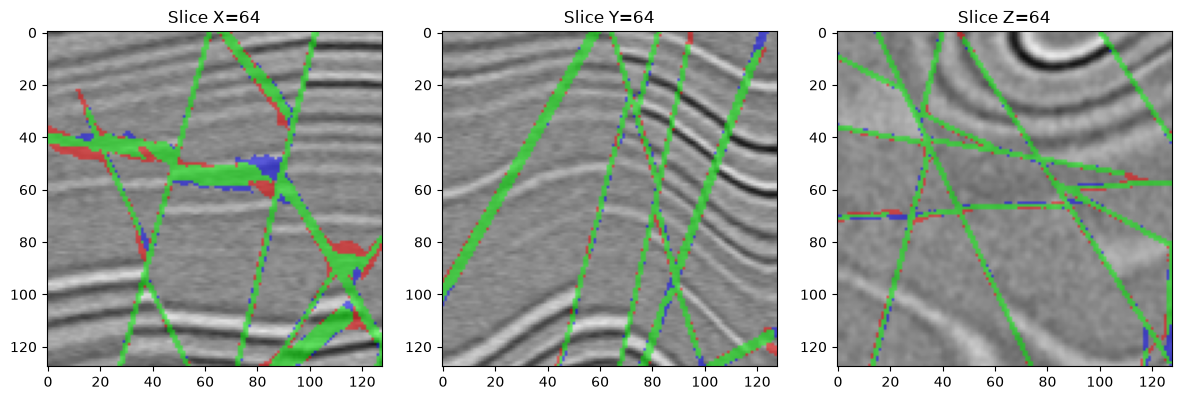

model_11 · resaceunet_grva | dataset_74/images/img_0093.npy


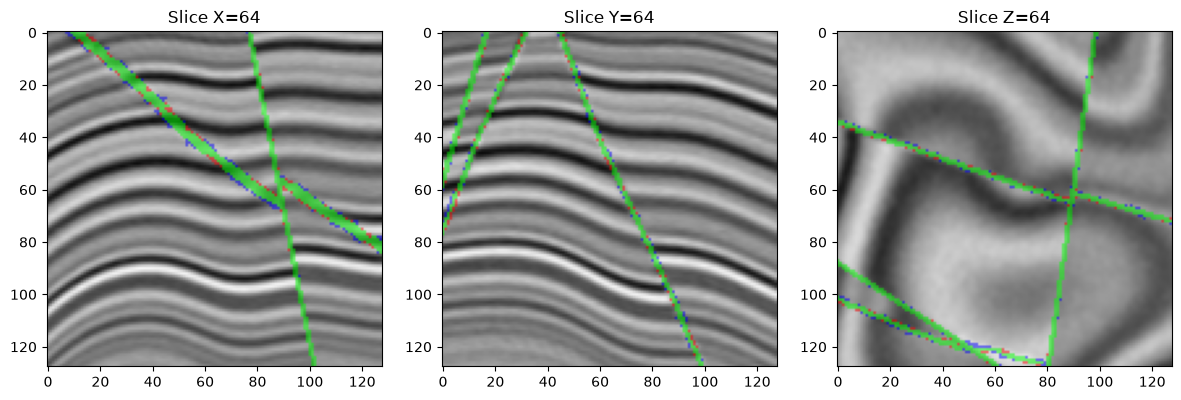

In [13]:
def plotPrediction(img, mask, pred, alpha=0.5):
    gray    = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    rgb     = np.stack((gray, gray, gray), axis=-1)
    overlay = rgb.copy()

    overlay[mask > 0]                = [0, 0, 255]
    overlay[pred > 0]                = [255, 0, 0]
    overlay[(mask > 0) & (pred > 0)] = [0, 255, 0]
    showTile(img=(rgb * (1 - alpha) + overlay * alpha).astype(np.uint8))


for name, test in selected.items():
    dataset = test['loader'].dataset

    for index, pred in enumerate(test['preds']):
        img, mask = dataset[index]
        print(f"{name} · {test['info']['model']['network']} | {'/'.join(dataset.df.img_path.iloc[dataset.blocks[index][0]].split('/')[-3:])}")
        plotPrediction(img.squeeze().numpy(), mask.squeeze().numpy(), pred)